# 01 — Análise exploratória (EDA)

**Objetivo:** juntar as bases coletadas na Parte 1, entender os dados e decidir a limpeza antes de construir a busca.

Entradas (geradas pelos scripts da pasta `src/`):
- `data/raw/wikipedia_books.jsonl`: coleta por ano (`collect_wikipedia.py`)
- `data/raw/extra_books.jsonl`: lista curada do BookTok (`collect_extra.py`)

Saída: `data/processed/books.parquet`, a base limpa usada nas próximas partes.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.figsize"] = (10, 4)

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(exist_ok=True)

## 1. Carregar e juntar as bases

Cada linha dos arquivos `.jsonl` é um livro em formato JSON, e `pd.read_json(..., lines=True)` lê esse formato direto.

A coluna `plot` foi renomeada para `summary`. O nome `plot` coincide com o método `df.plot` do pandas, e por isso `df.plot.str...` dá erro: é preciso usar `df["plot"]`. Renomear evita a armadilha.

In [2]:
by_year = pd.read_json(RAW / "wikipedia_books.jsonl", lines=True)
by_year["source"] = "wikipedia_ano"
curated = pd.read_json(RAW / "extra_books.jsonl", lines=True)

df = pd.concat([by_year, curated], ignore_index=True).rename(columns={"plot": "summary"})
print(f"{len(by_year)} da coleta por ano + {len(curated)} da lista curada = {len(df)} livros")
df.head(3)

10552 da coleta por ano + 19 da lista curada = 10571 livros


,pageid,title,year,author,genre,series,categories,summary,n_words,url,source
0,739474,1632 (novel),2000,Eric Flint,"Alternate history, novel",1632 series,"[1632 series, 2000 American novels, 2000 English-language novels, 2000 science fiction novels, A...","In the fictional town of Grantville, West Virginia (modeled on the real West Virginia town of Ma...",789,https://en.wikipedia.org/wiki/1632_(novel),wikipedia_ano
1,4507275,1633 (novel),2002,David Weber & Eric Flint,"Alternate history, novel",1632 series,"[1632 series, 2002 American novels, 2002 English-language novels, 2002 science fiction novels, A...","The series begins in the Modern era on May 31, 2000, during a small town wedding when the small ...",247,https://en.wikipedia.org/wiki/1633_(novel),wikipedia_ano
2,4543339,1634: The Ram Rebellion,2006,"Eric Flint, Virginia DeMarce",Alternate history,"1632 series, aka Ring of Fire series","[1632 series, 2006 American novels, 2006 English-language novels, Books by Eric Flint, Collabora...",The book spot-covers local events and a few related diplomatic discussions from a few days after...,845,https://en.wikipedia.org/wiki/1634:_The_Ram_Rebellion,wikipedia_ano


In [3]:
# Porcentagem de valores ausentes por coluna
(df.isna().mean() * 100).round(1).sort_values(ascending=False)

series        69.9
genre         20.5
author        13.1
year           0.0
title          0.0
pageid         0.0
categories     0.0
summary        0.0
n_words        0.0
url            0.0
source         0.0
dtype: float64

`series` vazia é esperado, porque a maioria dos livros não faz parte de série. `author` e `genre` vêm do infobox da página, que nem todo artigo tem. Para o gênero, as **categorias** da Wikipédia (sempre presentes) servem de complemento na seção 6.

## 2. Remover light novels

A categoria `{ano} Japanese novels` trouxe centenas de *light novels*: romances curtos japoneses, ligados a anime e mangá, dos gêneros *isekai* e *harém*. Elas não fazem parte do foco do projeto, que são os livros populares entre leitores jovens do Ocidente e do BookTok. As páginas costumam descrever a franquia inteira, e quase nunca têm autor no infobox.

**Decisão:** remover os livros com "light novel" nas categorias ou com isekai/harém/light novel no gênero. Para incluí-las de volta, basta comentar a linha do filtro.

In [4]:
categories_text = df["categories"].apply(lambda cats: " | ".join(cats).lower())
genre_text = df["genre"].fillna("").str.lower()

is_light_novel = categories_text.str.contains("light novel") | genre_text.str.contains("isekai|harem|light novel")
print(f"Light novels: {is_light_novel.sum()} ({is_light_novel.mean():.1%} da base)")
df.loc[is_light_novel, ["title", "author", "genre"]].sample(5, random_state=1)

Light novels: 815 (7.7% da base)


,title,author,genre
3968,Kino's Journey,NaN,"Adventure, Philosophical, Science fiction"
5057,"Oh Boy, Was I Wrong About Her",NaN,Romantic comedy
4047,Lance N' Masques,NaN,"Action, Fantasy"
6123,Shin Honkaku Mahō Shōjo Risuka,NaN,Magical girl
197,A Gentle Noble's Vacation Recommendation,NaN,"Adventure, fantasy"


In [5]:
df = df[~is_light_novel].reset_index(drop=True)
print(f"Restam {len(df)} livros")

Restam 9756 livros


## 3. Duplicados

O mesmo livro pode aparecer com títulos ligeiramente diferentes, por exemplo `The Princess Diaries` e `The Princess Diaries (novel)`. Para comparar, normalizamos o título: minúsculas e sem o complemento entre parênteses. Depois juntamos o título normalizado com o autor.

Entre as cópias, fica a que tem o **resumo mais longo**.

In [6]:
def clean_title(title):
    """Remove o complemento de desambiguação da Wikipédia: 'Circe (novel)' -> 'Circe'."""
    return re.sub(r"\s*\([^()]*\)$", "", title).strip()

df["title_clean"] = df["title"].apply(clean_title)
key = df["title_clean"].str.lower() + "|" + df["author"].fillna("").str.lower()

duplicated = key.duplicated(keep=False)
print(f"Livros com duplicata: {duplicated.sum()}")
df.loc[duplicated, ["title", "author", "year", "n_words"]].sort_values("title")

Livros com duplicata: 6


,title,author,year,n_words
2780,The A-List (novel series),Zoey Dean,2004,132
6137,The A-List (novel),Zoey Dean,2003,528
8005,The Princess Diaries,Meg Cabot,2006,260
8009,The Princess Diaries (novel),Meg Cabot,2000,348
135,The School for Good and Evil,Soman Chainani,2019,2230
8235,The School for Good and Evil (novel),Soman Chainani,2013,1148


In [7]:
df = (df.assign(key=key)
        .sort_values("n_words", ascending=False)
        .drop_duplicates("key")
        .drop(columns="key")
        .sort_index()
        .reset_index(drop=True))
print(f"Restam {len(df)} livros")

Restam 9753 livros


## 4. Livros por ano

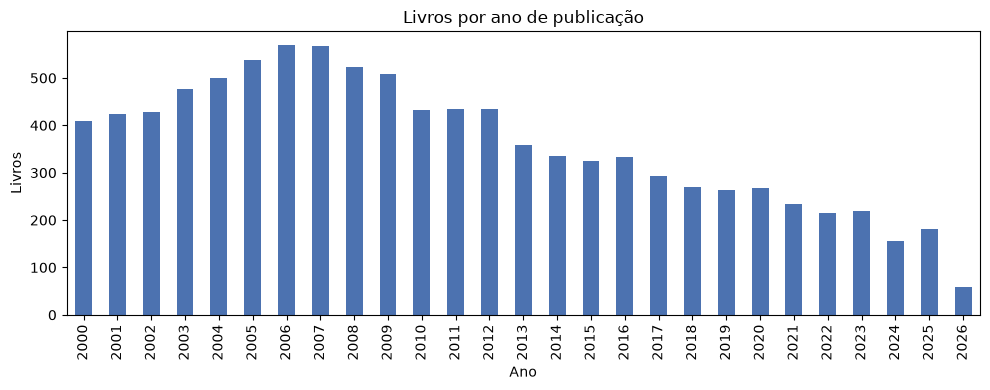

In [8]:
ax = df["year"].value_counts().sort_index().plot.bar(color="#4C72B0")
ax.set(title="Livros por ano de publicação", xlabel="Ano", ylabel="Livros")
plt.tight_layout()

Os anos recentes têm **menos** livros, e isso não quer dizer que se publica menos. Os artigos da Wikipédia vão sendo escritos ao longo dos anos depois do lançamento, então os livros mais novos ainda estão "chegando". 2026 está incompleto.

Na prática, os livros de 2023 a 2026 estão sub-representados, e a lista curada (Parte 1b) ajuda a garantir os mais populares.

## 5. Tamanho dos resumos

### 5.1 Em palavras

In [9]:
df["n_words"].describe().round(0)

count     9753.0
mean       374.0
std        403.0
min         30.0
25%        105.0
50%        238.0
75%        544.0
max      10117.0
Name: n_words, dtype: float64

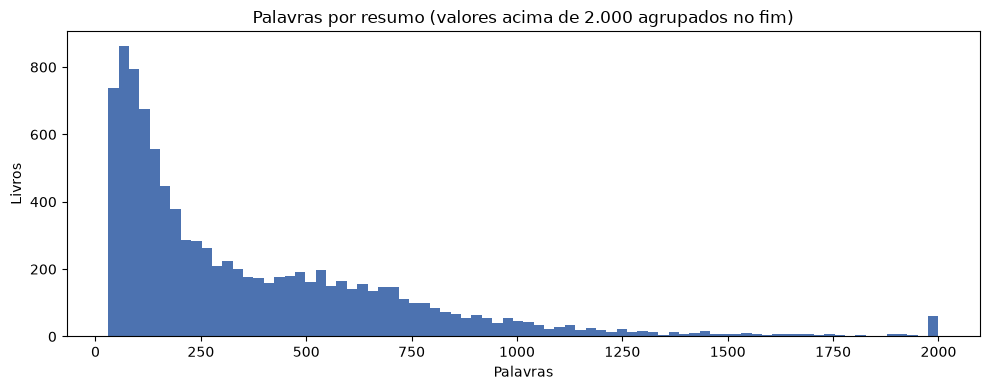

In [10]:
ax = df["n_words"].clip(upper=2000).plot.hist(bins=80, color="#4C72B0")
ax.set(title="Palavras por resumo (valores acima de 2.000 agrupados no fim)", xlabel="Palavras", ylabel="Livros")
plt.tight_layout()

A distribuição é bem **assimétrica**: metade dos resumos tem até ~220 palavras, mas há uma cauda longa, com alguns passando de 5 mil palavras (geralmente páginas que resumem uma série inteira).

**Resumos curtos demais** trazem poucos detalhes para a busca. Veja quantos livros cada corte mínimo removeria:

In [11]:
for minimum in [30, 40, 50, 60, 80]:
    print(f"menos de {minimum} palavras: {(df['n_words'] < minimum).sum():>5} livros")

menos de 30 palavras:     0 livros
menos de 40 palavras:   231 livros
menos de 50 palavras:   556 livros
menos de 60 palavras:   903 livros
menos de 80 palavras:  1600 livros


In [12]:
# Como são os resumos entre 30 e 40 palavras?
for _, row in df[df["n_words"].between(30, 39)].sample(3, random_state=0).iterrows():
    print(f"{row['title']} ({row['n_words']} palavras)\n  {row['summary']}\n")

Waiting for an Angel (33 palavras)
  The novel is set during the military rule of General Sani Abacha. It focuses mainly on Lomba; a journalist and editor at The Dial who is imprisoned for fabricating "lies" against the government.

The Ballad of Desmond Kale (31 palavras)
  Desmond Kale escapes from his detention at Botany Bay and heads into the bush to look after a flock of Merino sheep. Meanwhile the wardens at the prison seek his re-arrest.

The Last Confession (novel) (33 palavras)
  The novel concerns the trials and imprisonment of Giordano Bruno who was burned at the stake for heresy in 1600. It details Bruno's life, his religious beliefs and his final days in prison.



**Decisão:** manter os resumos com **pelo menos 40 palavras**. Abaixo disso, o texto costuma ser uma frase genérica ("um romance sobre amor e perda"). O corte em 40 ainda preserva livros da lista curada com resumo curto, como *House of Sky and Breath* (44 palavras). Não há corte máximo: os resumos longos são tratados com *chunks* (seção 5.2).

In [13]:
MIN_WORDS = 40
df = df[df["n_words"] >= MIN_WORDS].reset_index(drop=True)
print(f"Restam {len(df)} livros")

Restam 9522 livros


### 5.2 Em tokens

O modelo **não lê palavras, e sim *tokens***, os pedaços de palavra definidos pelo seu tokenizador. Vamos usar o tokenizador do `all-MiniLM-L6-v2`, o modelo das Partes 3 e 4. Na primeira execução, ele é baixado do Hugging Face (alguns MB) e depois fica em cache.

In [14]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")

example = "Violet Sorrengail is forced to become a dragon rider."
print(tokenizer.tokenize(example))

['violet', 'so', '##rre', '##nga', '##il', 'is', 'forced', 'to', 'become', 'a', 'dragon', 'rider', '.']


Repare que palavras comuns viram um token só, enquanto nomes raros são quebrados em pedaços (os que começam com `##` continuam a palavra anterior). Por isso o número de tokens é sempre **maior** que o de palavras.

Agora, os tokens de todos os resumos. O aviso de "sequence length is longer than the specified maximum" é esperado: estamos só contando os tokens, sem passar nada pelo modelo.

In [15]:
encoded = tokenizer(df["summary"].tolist(), add_special_tokens=True)
df["n_tokens"] = [len(ids) for ids in encoded["input_ids"]]

print(f"Tokens por palavra (mediana): {(df['n_tokens'] / df['n_words']).median():.2f}")
df["n_tokens"].describe().round(0)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1023 > 512). Running this sequence through the model will result in indexing errors


Tokens por palavra (mediana): 1.28


count     9522.0
mean       492.0
std        526.0
min         45.0
25%        142.0
50%        320.0
75%        709.0
max      13964.0
Name: n_tokens, dtype: float64

Resumos acima de 256 tokens: 56.2%


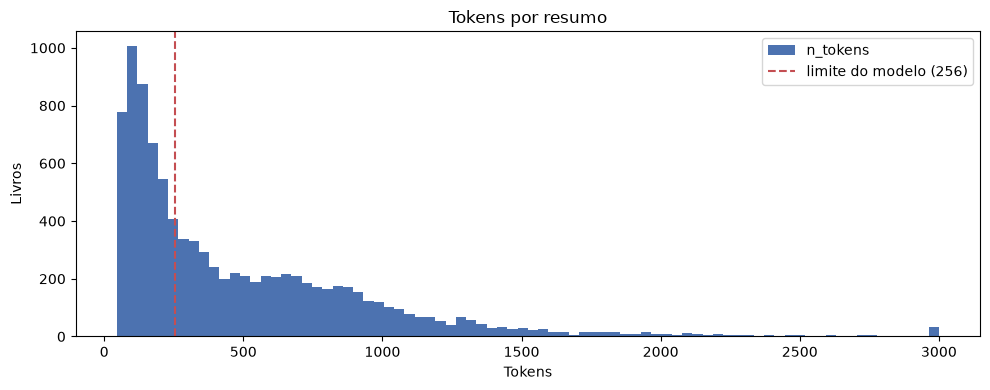

In [16]:
MAX_TOKENS = 256  # limite de entrada do all-MiniLM-L6-v2

ax = df["n_tokens"].clip(upper=3000).plot.hist(bins=80, color="#4C72B0")
ax.axvline(MAX_TOKENS, color="#C44E52", linestyle="--", label=f"limite do modelo ({MAX_TOKENS})")
ax.set(title="Tokens por resumo", xlabel="Tokens", ylabel="Livros")
ax.legend()
plt.tight_layout()

print(f"Resumos acima de {MAX_TOKENS} tokens: {(df['n_tokens'] > MAX_TOKENS).mean():.1%}")

### Por que isso importa: truncamento

O `all-MiniLM-L6-v2` aceita no máximo **256 tokens** por texto. O que passa disso é **truncado**, ou seja, simplesmente ignorado. Num resumo de 1.000 tokens, o modelo leria só o primeiro quarto da história. Se a pessoa lembrar do *final* do livro, a busca não encontraria.

Na CPU, há também uma questão de custo: o tempo de processamento cresce mais que linearmente com o tamanho do texto, por causa da atenção do Transformer. Por isso mantemos o limite baixo.

**Decisão:** guardar o resumo **completo** na base. Na Parte 3, cada resumo longo será dividido em **pedaços (*chunks*) de até ~256 tokens**, cada pedaço vira um embedding, e a busca compara a consulta com todos os pedaços. O livro recebe a nota do seu melhor pedaço. Assim, nenhuma parte da história se perde.

## 6. Gêneros simplificados

O campo `genre` do infobox é texto livre ("Fantasy, Young Adult", "Psychological thriller, Gothic fiction"...) e falta em parte dos livros. Para usar como **filtro na demo**, criamos rótulos simples a partir do `genre` **e** das categorias da Wikipédia. Um livro pode ter vários rótulos (ex.: fantasia + romance + jovem adulto).

In [17]:
GENRE_RULES = {
    "fantasia": r"fantasy|fairy tale|sword and sorcery",
    "ficção científica": r"science fiction|sci-fi|cyberpunk|space opera",
    "distopia": r"dystopi|apocalyptic",
    "romance": r"romance|romantic|love stor|chick lit",
    "thriller/suspense": r"thriller|suspense",
    "mistério/policial": r"mystery|crime|detective|noir|whodunit|police procedural",
    "terror": r"horror|ghost stor",
    "jovem adulto": r"young adult|\bteen",
    "infantojuvenil": r"children's|middle grade|middle-grade",
    "histórico": r"historical",
    "literário": r"literary fiction|literary novel",
    "LGBTQ+": r"lgbt|lesbian|\bgay\b|queer|bisexual|transgender",
}

def simple_genres(row):
    text = (str(row["genre"] or "") + " | " + " | ".join(row["categories"])).lower()
    return [label for label, pattern in GENRE_RULES.items() if re.search(pattern, text)]

df["genres"] = df.apply(simple_genres, axis=1)
print(f"Livros sem nenhum rótulo: {(df['genres'].str.len() == 0).mean():.1%}")

Livros sem nenhum rótulo: 23.1%


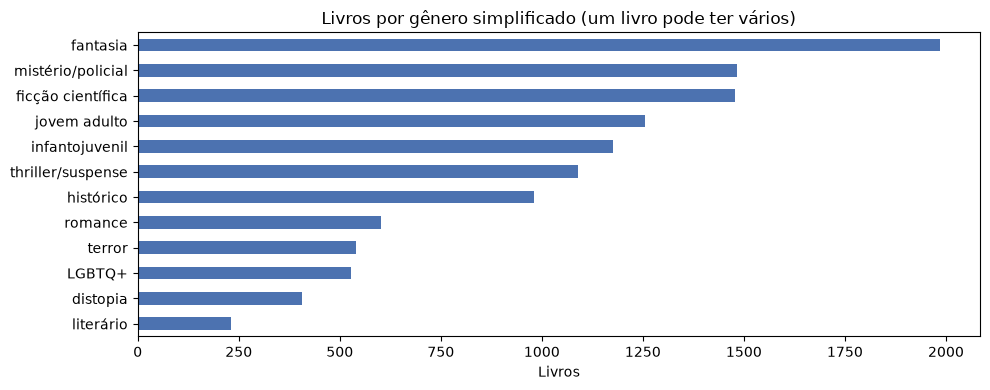

In [18]:
ax = df["genres"].explode().value_counts().sort_values().plot.barh(color="#4C72B0")
ax.set(title="Livros por gênero simplificado (um livro pode ter vários)", xlabel="Livros", ylabel="")
plt.tight_layout()

In [19]:
# Conferindo alguns livros conhecidos
famous = ["Fourth Wing", "A Court of Thorns and Roses", "It Ends with Us", "The Seven Husbands of Evelyn Hugo", "The Silent Patient"]
df.loc[df["title_clean"].isin(famous), ["title_clean", "author", "year", "genres"]]

,title_clean,author,year,genres
2595,Fourth Wing,Rebecca Yarros,2023,"[fantasia, distopia, romance]"
3391,It Ends with Us,Colleen Hoover,2016,[romance]
8069,The Seven Husbands of Evelyn Hugo,Taylor Jenkins Reid,2017,"[histórico, LGBTQ+]"
8149,The Silent Patient,Alex Michaelides,2019,"[thriller/suspense, mistério/policial]"
9503,A Court of Thorns and Roses,Sarah J. Maas,2015,"[fantasia, romance, jovem adulto]"


## 7. Salvar a base limpa

In [20]:
books = (df.assign(book_id=range(len(df)))
           [["book_id", "title_clean", "author", "year", "genres", "genre", "series",
             "summary", "n_words", "n_tokens", "url", "source"]]
           .rename(columns={"title_clean": "title", "genre": "genre_raw"}))

books.to_parquet(PROCESSED / "books.parquet", index=False)
print(f"Salvo: {PROCESSED / 'books.parquet'} — {len(books)} livros, {books.shape[1]} colunas")
books.head(3)

Salvo: ..\data\processed\books.parquet — 9522 livros, 12 colunas


,book_id,title,author,year,genres,genre_raw,series,summary,n_words,n_tokens,url,source
0,0,1632,Eric Flint,2000,[ficção científica],"Alternate history, novel",1632 series,"In the fictional town of Grantville, West Virginia (modeled on the real West Virginia town of Ma...",789,1023,https://en.wikipedia.org/wiki/1632_(novel),wikipedia_ano
1,1,1633,David Weber & Eric Flint,2002,[ficção científica],"Alternate history, novel",1632 series,"The series begins in the Modern era on May 31, 2000, during a small town wedding when the small ...",247,322,https://en.wikipedia.org/wiki/1633_(novel),wikipedia_ano
2,2,1634: The Ram Rebellion,"Eric Flint, Virginia DeMarce",2006,[ficção científica],Alternate history,"1632 series, aka Ring of Fire series",The book spot-covers local events and a few related diplomatic discussions from a few days after...,845,1083,https://en.wikipedia.org/wiki/1634:_The_Ram_Rebellion,wikipedia_ano


## Resumo das decisões

| Decisão | Motivo |
|---|---|
| Remover light novels | Fora do foco (BookTok/YA ocidental); páginas de franquia, quase sem autor |
| Deduplicar por título normalizado + autor, mantendo o maior resumo | O mesmo livro aparecia com títulos ligeiramente diferentes |
| Mínimo de 40 palavras por resumo; sem máximo | Abaixo disso há pouca informação; 40 preserva livros da lista curada |
| Guardar o resumo completo e usar *chunks* de ~256 tokens na Parte 3 | O modelo trunca em 256 tokens; sem *chunks*, perderíamos o meio e o fim das histórias |
| Gêneros simplificados (multirrótulo) a partir do infobox + categorias | O campo de gênero é livre e incompleto; os rótulos servem de filtro na demo |

**Próximo passo (Parte 2):** dividir os livros em treino/validação/teste e montar o conjunto de consultas de avaliação.